In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re
import docx
import textract
from pypdf import PdfReader
from collections import Counter
import zipfile

In [2]:
dataset_path = "dataset"

data = []

for root, dirs, files in os.walk(dataset_path):

    for file in files:

        file_path = os.path.join(root, file)

        category = os.path.basename(root)

        data.append({
            "filename": file,
            "filepath": file_path,
            "category": category
        })

df = pd.DataFrame(data)
df

,filename,filepath,category
0,Peoplesoft Admin_G Ananda Rayudu.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft\P...,Peoplesoft
1,Peoplesoft Admin_AnubhavSingh.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft Resume
2,Peoplesoft Admin_G Ananda Rayudu.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft Resume
3,Peoplesoft Admin_Gangareddy.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft Resume
4,Peoplesoft Admin_Murali.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft Resume
...,...,...,...
75,Sri Krishna S_Hexaware.doc,dataset\P637 Dataset\Resumes_Docx\workday\Sri ...,workday
76,Srikanth-Hexaware.docx,dataset\P637 Dataset\Resumes_Docx\workday\Srik...,workday
77,SSKumar_Hexaware.docx,dataset\P637 Dataset\Resumes_Docx\workday\SSKu...,workday
78,Venkateswarlu B_Hexaware.doc,dataset\P637 Dataset\Resumes_Docx\workday\Venk...,workday


In [3]:
df.shape

(80, 3)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   filename  80 non-null     object
 1   filepath  80 non-null     object
 2   category  80 non-null     object
dtypes: object(3)
memory usage: 2.0+ KB


In [5]:
df['category'] = df['category'].replace({
    'Peoplesoft Resume': 'Peoplesoft',
    'workday': 'Workday'
})

In [6]:
df

,filename,filepath,category
0,Peoplesoft Admin_G Ananda Rayudu.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft\P...,Peoplesoft
1,Peoplesoft Admin_AnubhavSingh.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft
2,Peoplesoft Admin_G Ananda Rayudu.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft
3,Peoplesoft Admin_Gangareddy.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft
4,Peoplesoft Admin_Murali.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft
...,...,...,...
75,Sri Krishna S_Hexaware.doc,dataset\P637 Dataset\Resumes_Docx\workday\Sri ...,Workday
76,Srikanth-Hexaware.docx,dataset\P637 Dataset\Resumes_Docx\workday\Srik...,Workday
77,SSKumar_Hexaware.docx,dataset\P637 Dataset\Resumes_Docx\workday\SSKu...,Workday
78,Venkateswarlu B_Hexaware.doc,dataset\P637 Dataset\Resumes_Docx\workday\Venk...,Workday


In [7]:
df.isnull().sum()

filename    0
filepath    0
category    0
dtype: int64

In [8]:
df['category'].value_counts()

category
React Developer    24
Peoplesoft         21
Workday            21
SQL Developer      14
Name: count, dtype: int64

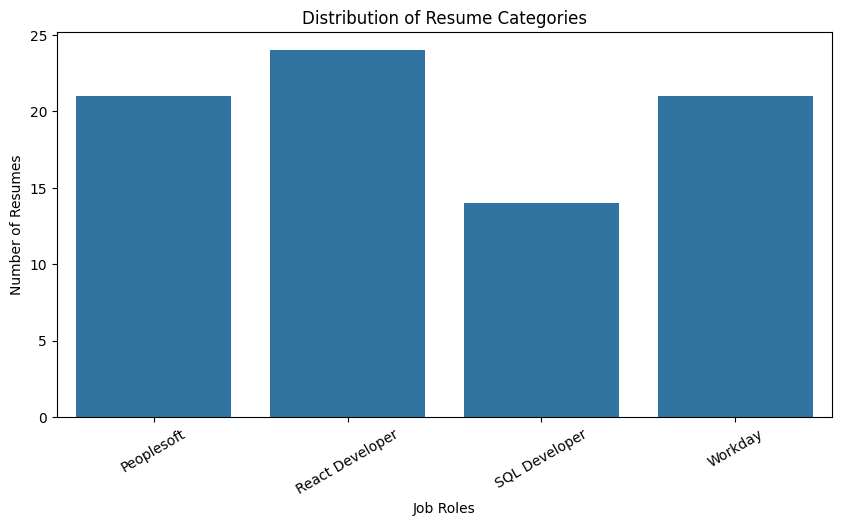

In [9]:
plt.figure(figsize=(10,5))

sns.countplot(data=df, x='category')

plt.title("Distribution of Resume Categories")
plt.xlabel("Job Roles")
plt.ylabel("Number of Resumes")
plt.xticks(rotation=30)

plt.show()

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df['filename'].duplicated().sum()

np.int64(0)

In [12]:
df.describe(include='all')

,filename,filepath,category
count,80,80,80
unique,80,80,4
top,Peoplesoft Admin_G Ananda Rayudu.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft\P...,React Developer
freq,1,1,24


In [13]:


def extract_text(file_path):

    extension = os.path.splitext(file_path)[1].lower()

    try:

        if extension == '.docx':

            # Check whether the DOCX structure is valid
            with zipfile.ZipFile(file_path, 'r') as z:

                if 'word/document.xml' not in z.namelist():
                    print("Invalid DOCX structure:", file_path)
                    return ""

            document = docx.Document(file_path)

            text = []

            for paragraph in document.paragraphs:
                text.append(paragraph.text)

            for table in document.tables:
                for row in table.rows:
                    for cell in row.cells:
                        text.append(cell.text)

            return " ".join(text)

        elif extension == '.doc':

            return textract.process(
                file_path,
                extension='doc'
            ).decode('utf-8', errors='ignore')

        elif extension == '.pdf':

            reader = PdfReader(file_path)

            return " ".join(
                page.extract_text() or ""
                for page in reader.pages
            )

        return ""

    except Exception as e:

        print("Extraction failed:", file_path)
        print("Reason:", e)

        return ""

In [14]:
print("Total files:", len(df))

print(df['filepath'].str.lower().str.endswith('.doc').sum(), "DOC files")
print(df['filepath'].str.lower().str.endswith('.docx').sum(), "DOCX files")
print(df['filepath'].str.lower().str.endswith('.pdf').sum(), "PDF files")

Total files: 80
26 DOC files
53 DOCX files
1 PDF files


In [15]:
valid_files = df[
    df['filepath'].str.lower().str.endswith('.docx')
]

for path in valid_files['filepath']:

    text = extract_text(path)

    if len(text) > 0:
        print("Successfully extracted:", path)
        print(text[:500])
        break

Invalid DOCX structure: dataset\P637 Dataset\Resumes_Docx\Peoplesoft\Peoplesoft Admin_G Ananda Rayudu.docx
Successfully extracted: dataset\P637 Dataset\Resumes_Docx\Peoplesoft Resume\Peoplesoft Admin_AnubhavSingh.docx
  Anubhav Kumar Singh		    To work in a globally competitive environment on    challenging assignments that shall yield the    twin benefits of the job satisfaction and a steady-paced    professional growth.                Professional Experience   06/2019 - Current	HCL										 			Current Role: System Admin Offshore 			Skills : Shell Scripting, Linux , PeopleSoft Administration , Github  Managing PeopleSoft HCM and PeopleSoft FSCM production environments along with support environments install


In [16]:
from tqdm.notebook import tqdm

resume_texts = []

for path in tqdm(df['filepath'], desc="Extracting resumes"):

    text = extract_text(path)

    resume_texts.append(text)

df['resume_text'] = resume_texts

Extracting resumes:   0%|          | 0/80 [00:00<?, ?it/s]

Invalid DOCX structure: dataset\P637 Dataset\Resumes_Docx\Peoplesoft\Peoplesoft Admin_G Ananda Rayudu.docx


In [17]:
df['text_length'] = df['resume_text'].str.len()

print("Total resumes:", len(df))

print("Successfully extracted:",
      (df['text_length'] > 0).sum())

print("Failed extraction:",
      (df['text_length'] == 0).sum())

Total resumes: 80
Successfully extracted: 79
Failed extraction: 1


In [18]:
df[['filename', 'category', 'resume_text']].head()

,filename,category,resume_text
0,Peoplesoft Admin_G Ananda Rayudu.docx,Peoplesoft,
1,Peoplesoft Admin_AnubhavSingh.docx,Peoplesoft,Anubhav Kumar Singh\t\t To work in a glob...
2,Peoplesoft Admin_G Ananda Rayudu.doc,Peoplesoft,\n\n\n\n\n\n\t\n\nProfile Summary:\t\t\t\t\t\t...
3,Peoplesoft Admin_Gangareddy.doc,Peoplesoft,PeopleSoft Database Administrator\n ...
4,Peoplesoft Admin_Murali.docx,Peoplesoft,Murali Experience Summary I have 6 years of...


In [19]:
# Remove null values
df = df.dropna(subset=['resume_text'])

# Remove empty resumes
df = df[df['resume_text'].str.strip() != '']

# Remove duplicate resumes
df = df.drop_duplicates(subset=['resume_text'])

In [20]:
df

,filename,filepath,category,resume_text,text_length
1,Peoplesoft Admin_AnubhavSingh.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,Anubhav Kumar Singh\t\t To work in a glob...,7447
2,Peoplesoft Admin_G Ananda Rayudu.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,\n\n\n\n\n\n\t\n\nProfile Summary:\t\t\t\t\t\t...,8443
3,Peoplesoft Admin_Gangareddy.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,PeopleSoft Database Administrator\n ...,7062
4,Peoplesoft Admin_Murali.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,Murali Experience Summary I have 6 years of...,4594
5,Peoplesoft Admin_Priyanka Ramadoss.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,"Priyanka Ramadoss\n61/46, MountPleasant, \nCoo...",5374
...,...,...,...,...,...
75,Sri Krishna S_Hexaware.doc,dataset\P637 Dataset\Resumes_Docx\workday\Sri ...,Workday,\tWorkday Integration Consultant\n\nName ...,7239
76,Srikanth-Hexaware.docx,dataset\P637 Dataset\Resumes_Docx\workday\Srik...,Workday,Seeking suitable positions in Workday HCM as ...,6547
77,SSKumar_Hexaware.docx,dataset\P637 Dataset\Resumes_Docx\workday\SSKu...,Workday,WORKDAY | HCM | FCM Name \t\t: Kumar S.S Role...,8117
78,Venkateswarlu B_Hexaware.doc,dataset\P637 Dataset\Resumes_Docx\workday\Venk...,Workday,Venkateswarlu.B\t\t\t\t\t\t\t\tWorkday Consult...,6857


In [21]:
df.tail()

,filename,filepath,category,resume_text,text_length
75,Sri Krishna S_Hexaware.doc,dataset\P637 Dataset\Resumes_Docx\workday\Sri ...,Workday,\tWorkday Integration Consultant\n\nName ...,7239
76,Srikanth-Hexaware.docx,dataset\P637 Dataset\Resumes_Docx\workday\Srik...,Workday,Seeking suitable positions in Workday HCM as ...,6547
77,SSKumar_Hexaware.docx,dataset\P637 Dataset\Resumes_Docx\workday\SSKu...,Workday,WORKDAY | HCM | FCM Name \t\t: Kumar S.S Role...,8117
78,Venkateswarlu B_Hexaware.doc,dataset\P637 Dataset\Resumes_Docx\workday\Venk...,Workday,Venkateswarlu.B\t\t\t\t\t\t\t\tWorkday Consult...,6857
79,Vinay Kumar_Hexaware.docx,dataset\P637 Dataset\Resumes_Docx\workday\Vina...,Workday,...,5089


In [22]:
df['word_count'] = df['resume_text'].apply(
    lambda text: len(str(text).split())
)

In [23]:
df.head()

,filename,filepath,category,resume_text,text_length,word_count
1,Peoplesoft Admin_AnubhavSingh.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,Anubhav Kumar Singh\t\t To work in a glob...,7447,963
2,Peoplesoft Admin_G Ananda Rayudu.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,\n\n\n\n\n\n\t\n\nProfile Summary:\t\t\t\t\t\t...,8443,1053
3,Peoplesoft Admin_Gangareddy.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,PeopleSoft Database Administrator\n ...,7062,835
4,Peoplesoft Admin_Murali.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,Murali Experience Summary I have 6 years of...,4594,619
5,Peoplesoft Admin_Priyanka Ramadoss.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,"Priyanka Ramadoss\n61/46, MountPleasant, \nCoo...",5374,717


In [24]:
df[df['word_count'] > 0]['word_count'].describe()

count      79.000000
mean      722.670886
std       446.621584
min       200.000000
25%       414.000000
50%       602.000000
75%       906.000000
max      2682.000000
Name: word_count, dtype: float64

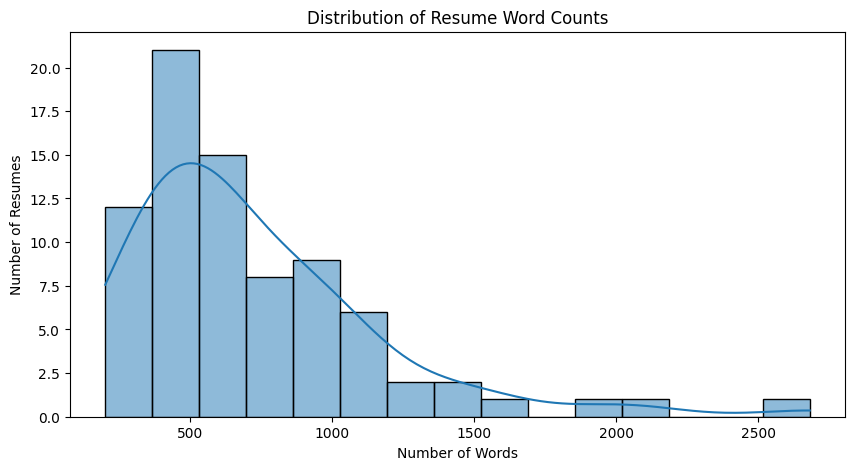

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df['word_count'] > 0],
    x='word_count',
    bins=15,
    kde=True
)

plt.title("Distribution of Resume Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Resumes")

plt.show()

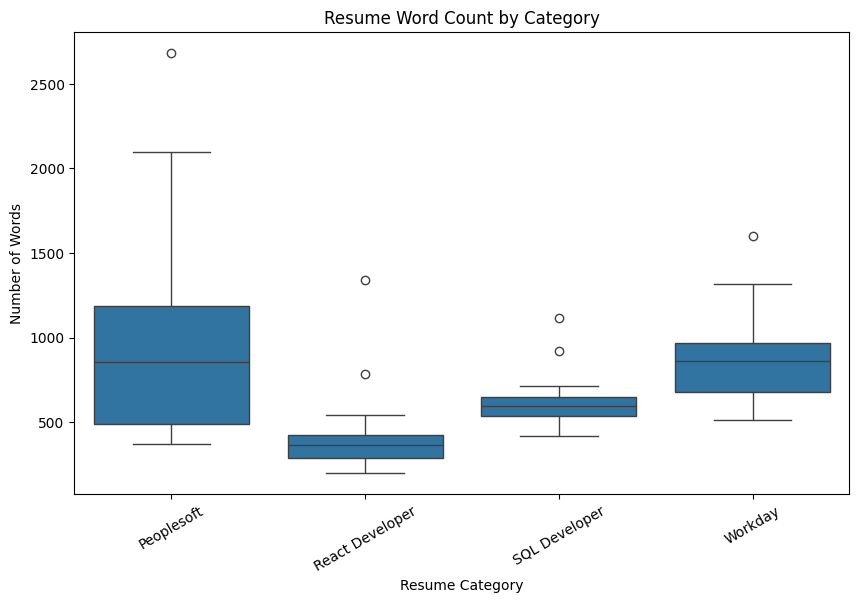

In [26]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df[df['word_count'] > 0],
    x='category',
    y='word_count'
)

plt.title("Resume Word Count by Category")
plt.xlabel("Resume Category")
plt.ylabel("Number of Words")

plt.xticks(rotation=30)

plt.show()

In [27]:
df[df['word_count'] > 0].groupby('category')['word_count'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
category,,,,,
Peoplesoft,20,996.700000,855.5,371,2682
React Developer,24,411.208333,363.5,200,1340
SQL Developer,14,637.928571,598.0,421,1115
Workday,21,874.142857,861.0,511,1601


In [28]:
#finding the most frequently occured words
from collections import Counter
import re

all_text = " ".join(
    df.loc[df['word_count'] > 0, 'resume_text']
)

words = re.findall(
    r'\b[a-zA-Z]+\b',
    all_text.lower()
)

word_counts = Counter(words)

print(word_counts.most_common(30))

[('and', 2883), ('the', 1417), ('in', 1315), ('to', 1141), ('of', 1043), ('on', 685), ('for', 684), ('experience', 584), ('peoplesoft', 451), ('with', 430), ('workday', 428), ('application', 416), ('as', 409), ('using', 395), ('server', 359), ('a', 344), ('data', 335), ('reports', 325), ('project', 323), ('from', 316), ('sql', 281), ('business', 273), ('database', 246), ('web', 245), ('process', 236), ('worked', 220), ('knowledge', 210), ('client', 198), ('involved', 191), ('tools', 190)]


In [29]:
#after removing the stop worsds
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

all_text = " ".join(
    df.loc[df['word_count'] > 0, 'resume_text']
).lower()

words = re.findall(r'\b[a-zA-Z]+\b', all_text)

filtered_words = [
    word for word in words
    if word not in ENGLISH_STOP_WORDS
]

filtered_counts = Counter(filtered_words)

print(filtered_counts.most_common(30))

[('experience', 584), ('peoplesoft', 451), ('workday', 428), ('application', 416), ('using', 395), ('server', 359), ('data', 335), ('reports', 325), ('project', 323), ('sql', 281), ('business', 273), ('database', 246), ('web', 245), ('process', 236), ('worked', 220), ('knowledge', 210), ('client', 198), ('involved', 191), ('tools', 190), ('integrations', 189), ('integration', 183), ('like', 180), ('support', 178), ('hcm', 177), ('development', 169), ('good', 165), ('team', 164), ('creating', 164), ('skills', 163), ('working', 159)]


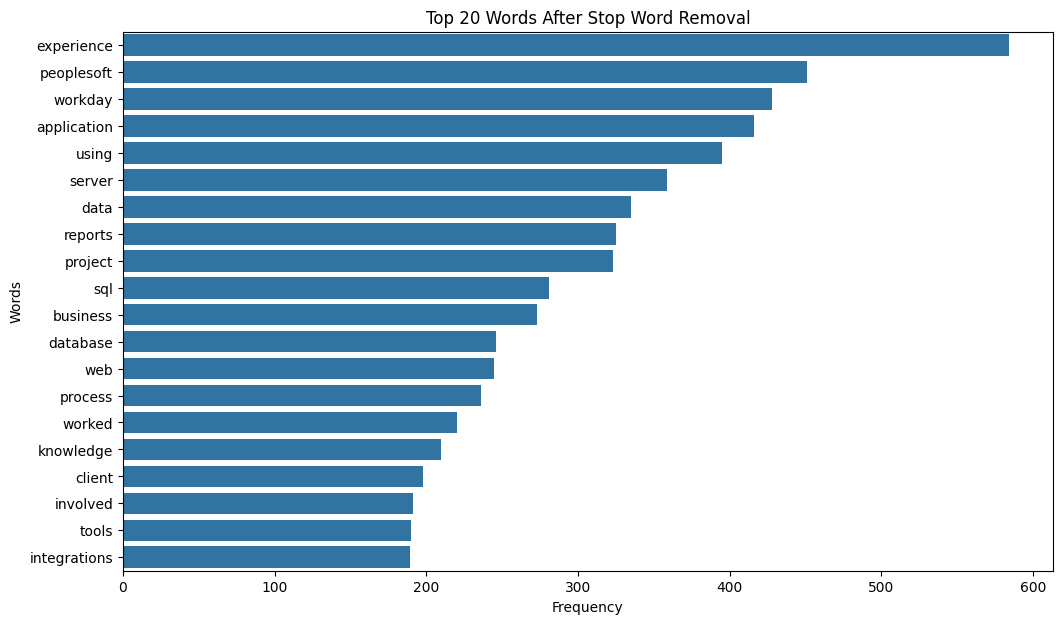

In [30]:
top_words = filtered_counts.most_common(20)

word_df = pd.DataFrame(
    top_words,
    columns=['word', 'frequency']
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=word_df,
    x='frequency',
    y='word'
)

plt.title("Top 20 Words After Stop Word Removal")
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.show()

In [31]:
for category in df['category'].unique():

    category_text = " ".join(
        df.loc[
            (df['category'] == category) &
            (df['word_count'] > 0),
            'resume_text'
        ].astype(str)
    ).lower()

    words = re.findall(
        r'\b[a-zA-Z]+\b',
        category_text
    )

    filtered_words = [
        word for word in words
        if word not in ENGLISH_STOP_WORDS
    ]

    word_counts = Counter(filtered_words)

    print("\nCategory:", category)
    print(word_counts.most_common(20))


Category: Peoplesoft
[('peoplesoft', 421), ('application', 307), ('server', 246), ('experience', 228), ('database', 164), ('servers', 146), ('process', 142), ('people', 133), ('tools', 118), ('web', 116), ('project', 114), ('oracle', 114), ('domains', 110), ('scheduler', 104), ('data', 93), ('reports', 85), ('support', 83), ('fscm', 82), ('environment', 81), ('production', 79)]

Category: React Developer
[('react', 144), ('js', 117), ('using', 90), ('experience', 90), ('project', 82), ('web', 73), ('javascript', 64), ('developer', 63), ('knowledge', 59), ('html', 56), ('skills', 53), ('application', 53), ('ui', 53), ('technologies', 48), ('design', 47), ('team', 46), ('good', 43), ('development', 43), ('used', 41), ('bootstrap', 40)]

Category: SQL Developer
[('sql', 227), ('data', 125), ('server', 107), ('experience', 104), ('using', 82), ('reports', 62), ('database', 62), ('functions', 61), ('project', 53), ('queries', 50), ('tables', 48), ('business', 45), ('knowledge', 45), ('proc

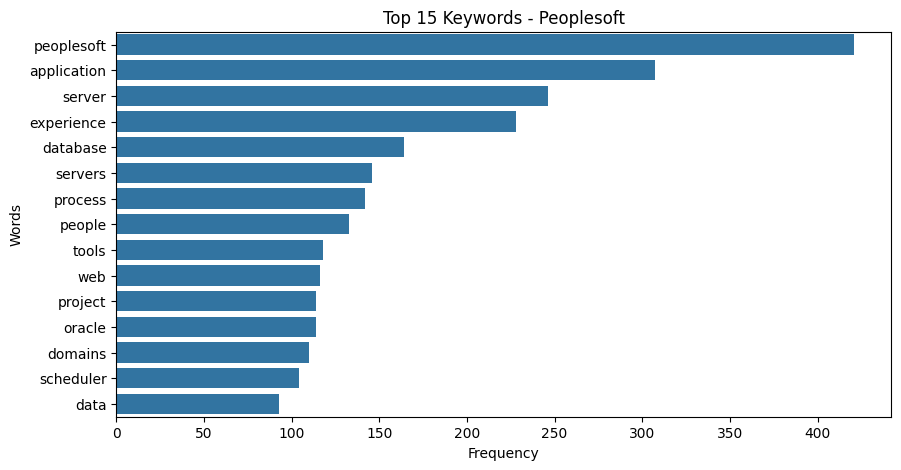

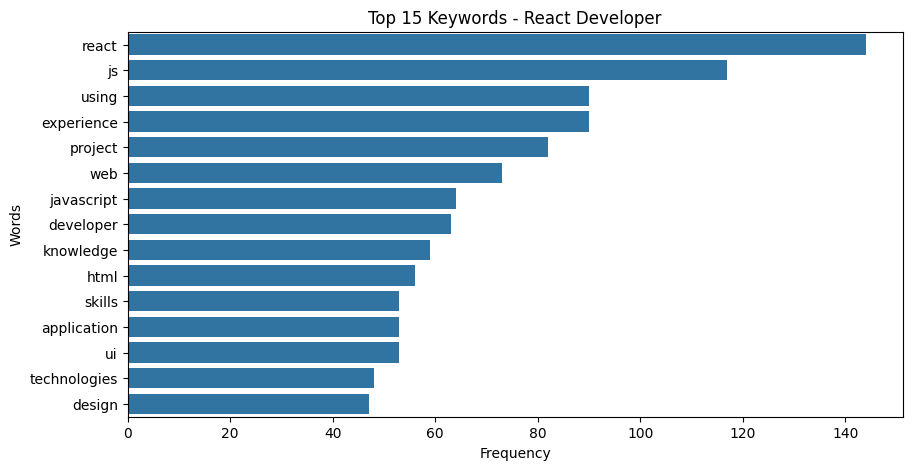

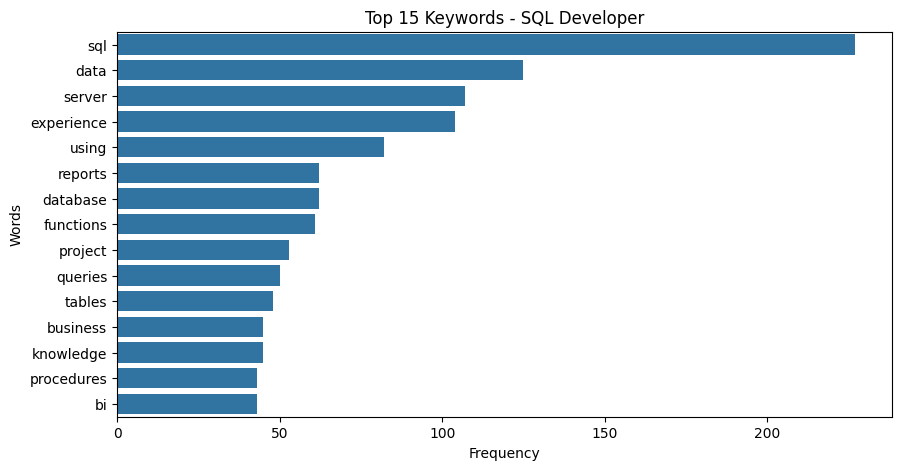

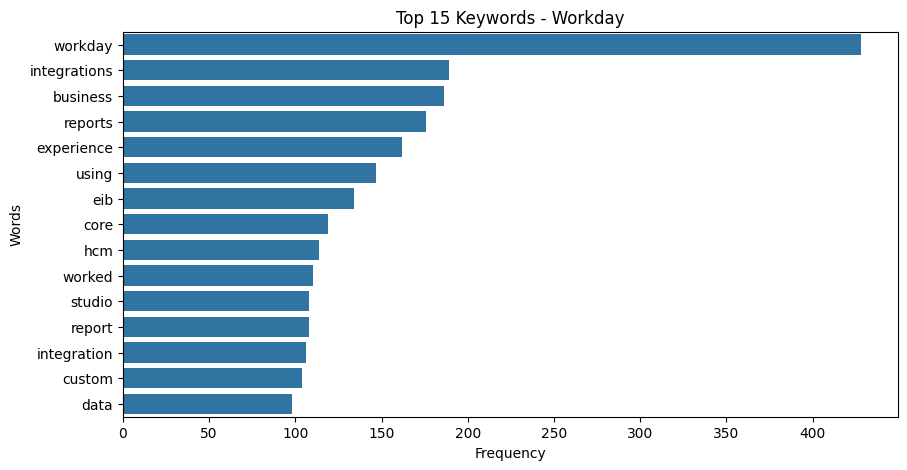

In [32]:
for category in df['category'].unique():

    category_text = " ".join(
        df.loc[
            (df['category'] == category) &
            (df['word_count'] > 0),
            'resume_text'
        ].astype(str)
    ).lower()

    words = re.findall(r'\b[a-zA-Z]+\b', category_text)

    filtered_words = [
        word for word in words
        if word not in ENGLISH_STOP_WORDS
    ]

    word_counts = Counter(filtered_words)

    top_words = word_counts.most_common(15)

    word_df = pd.DataFrame(
        top_words,
        columns=['word', 'frequency']
    )

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=word_df,
        x='frequency',
        y='word'
    )

    plt.title(f"Top 15 Keywords - {category}")
    plt.xlabel("Frequency")
    plt.ylabel("Words")

    plt.show()

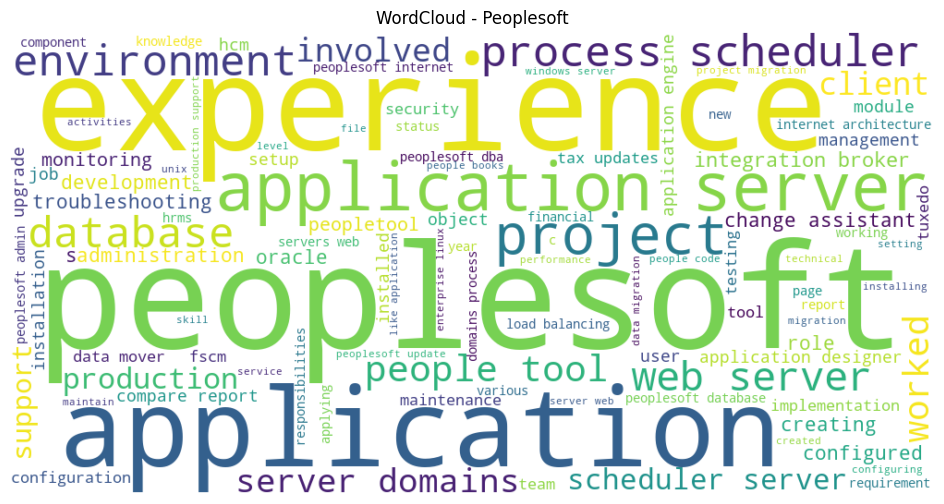

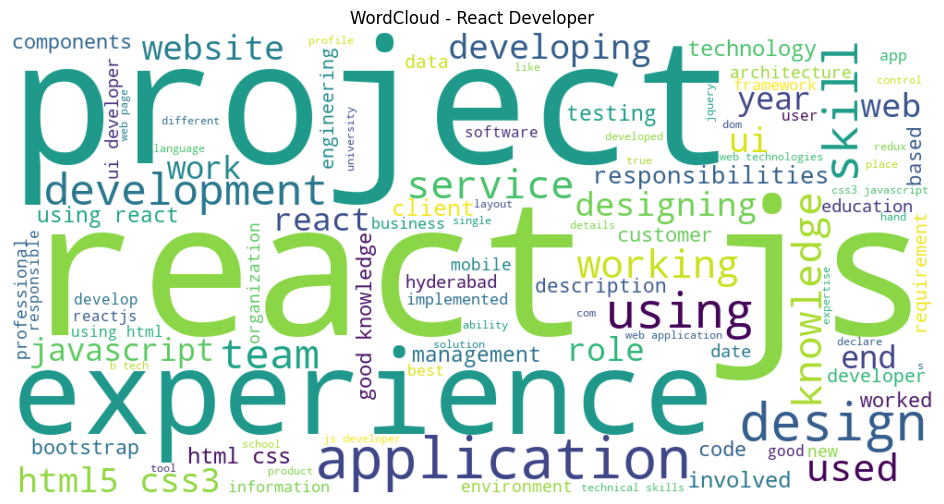

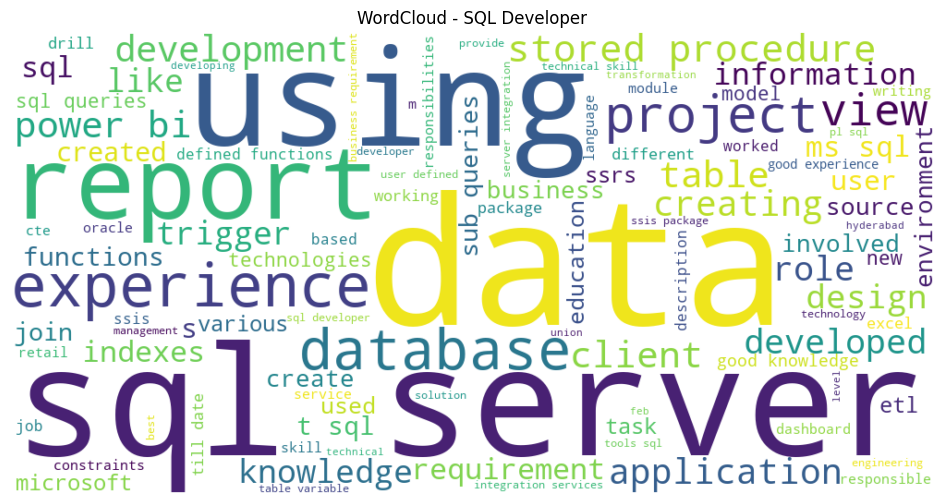

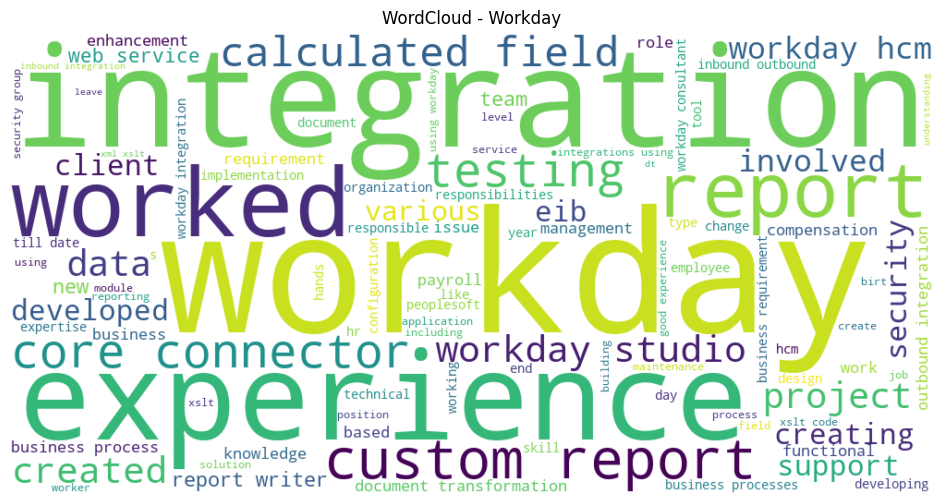

In [33]:
from wordcloud import WordCloud

for category in df['category'].unique():

    category_text = " ".join(
        df.loc[
            (df['category'] == category) &
            (df['word_count'] > 0),
            'resume_text'
        ].astype(str)
    ).lower()

    wordcloud = WordCloud(
        width=1000,
        height=500,
        background_color='white',
        stopwords=ENGLISH_STOP_WORDS,
        max_words=100
    ).generate(category_text)

    plt.figure(figsize=(12, 6))

    plt.imshow(wordcloud, interpolation='bilinear')

    plt.axis('off')

    plt.title(f"WordCloud - {category}")

    plt.show()

In [34]:
df_model = df[
    df['resume_text'].notna() &
    (df['resume_text'].str.strip() != '')
].copy()

print("Original dataset:", len(df))
print("Usable resumes:", len(df_model))

Original dataset: 79
Usable resumes: 79


In [35]:
df_model['cleaned_text'] = (
    df_model['resume_text'].str.lower()
)

In [36]:
df_model.head()

,filename,filepath,category,resume_text,text_length,word_count,cleaned_text
1,Peoplesoft Admin_AnubhavSingh.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,Anubhav Kumar Singh\t\t To work in a glob...,7447,963,anubhav kumar singh\t\t to work in a glob...
2,Peoplesoft Admin_G Ananda Rayudu.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,\n\n\n\n\n\n\t\n\nProfile Summary:\t\t\t\t\t\t...,8443,1053,\n\n\n\n\n\n\t\n\nprofile summary:\t\t\t\t\t\t...
3,Peoplesoft Admin_Gangareddy.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,PeopleSoft Database Administrator\n ...,7062,835,peoplesoft database administrator\n ...
4,Peoplesoft Admin_Murali.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,Murali Experience Summary I have 6 years of...,4594,619,murali experience summary i have 6 years of...
5,Peoplesoft Admin_Priyanka Ramadoss.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,"Priyanka Ramadoss\n61/46, MountPleasant, \nCoo...",5374,717,"priyanka ramadoss\n61/46, mountpleasant, \ncoo..."


In [37]:
df_model["cleaned_text"].iloc[0]

'  anubhav kumar singh\t\t    to work in a globally competitive environment on    challenging assignments that shall yield the    twin benefits of the job satisfaction and a steady-paced    professional growth.                professional experience   06/2019 - current\thcl\t\t\t\t\t\t\t\t\t\t \t\t\tcurrent role: system admin offshore \t\t\tskills : shell scripting, linux , peoplesoft administration , github  managing peoplesoft hcm and peoplesoft fscm production environments along with support environments installed on linux and windows os. involved in day to day activities such as project migration, database refresh, system admin changes, tax updates etc. troubleshooting of various servers like application servers, web servers, process scheduler servers. applying tuxedo and weblogic middleware cpu patches for various applications. working on shell scripting used as integration method for exchange of files to external systems installation and troubleshooting of 2-tier setup as per req

In [38]:

def remove_urls(text):
    text = re.sub(r'http\S+|www\S+', '', text)
    return text

df_model['cleaned_text'] = (
    df_model['cleaned_text'].apply(remove_urls)
)

In [39]:
def remove_emails(text):
    text=re.sub(r"\S+@\S+","",text)
    return text

df_model['cleaned_text']=(df_model['cleaned_text'].apply(remove_emails))

In [40]:
def remove_special_characters(text):
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    return text

df_model['cleaned_text'] = (
    df_model['cleaned_text'].apply(remove_special_characters)
)

In [41]:
def remove_extra_spaces(text):
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df_model['cleaned_text'] = (
    df_model['cleaned_text'].apply(remove_extra_spaces)
)

In [42]:
df_model.head()

,filename,filepath,category,resume_text,text_length,word_count,cleaned_text
1,Peoplesoft Admin_AnubhavSingh.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,Anubhav Kumar Singh\t\t To work in a glob...,7447,963,anubhav kumar singh to work in a globally comp...
2,Peoplesoft Admin_G Ananda Rayudu.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,\n\n\n\n\n\n\t\n\nProfile Summary:\t\t\t\t\t\t...,8443,1053,profile summary 7 years of experience in imple...
3,Peoplesoft Admin_Gangareddy.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,PeopleSoft Database Administrator\n ...,7062,835,peoplesoft database administrator gangareddy p...
4,Peoplesoft Admin_Murali.docx,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,Murali Experience Summary I have 6 years of...,4594,619,murali experience summary i have 6 years of ex...
5,Peoplesoft Admin_Priyanka Ramadoss.doc,dataset\P637 Dataset\Resumes_Docx\Peoplesoft R...,Peoplesoft,"Priyanka Ramadoss\n61/46, MountPleasant, \nCoo...",5374,717,priyanka ramadoss 61 46 mountpleasant coonoor ...


In [43]:
df_model[["filename","category","resume_text","cleaned_text"]].head()

,filename,category,resume_text,cleaned_text
1,Peoplesoft Admin_AnubhavSingh.docx,Peoplesoft,Anubhav Kumar Singh\t\t To work in a glob...,anubhav kumar singh to work in a globally comp...
2,Peoplesoft Admin_G Ananda Rayudu.doc,Peoplesoft,\n\n\n\n\n\n\t\n\nProfile Summary:\t\t\t\t\t\t...,profile summary 7 years of experience in imple...
3,Peoplesoft Admin_Gangareddy.doc,Peoplesoft,PeopleSoft Database Administrator\n ...,peoplesoft database administrator gangareddy p...
4,Peoplesoft Admin_Murali.docx,Peoplesoft,Murali Experience Summary I have 6 years of...,murali experience summary i have 6 years of ex...
5,Peoplesoft Admin_Priyanka Ramadoss.doc,Peoplesoft,"Priyanka Ramadoss\n61/46, MountPleasant, \nCoo...",priyanka ramadoss 61 46 mountpleasant coonoor ...


In [44]:
index = 0

print("ORIGINAL TEXT:\n")
print(df_model['resume_text'].iloc[index][:1000])

print("\nCLEANED TEXT:\n")
print(df_model['cleaned_text'].iloc[index][:1000])

ORIGINAL TEXT:

  Anubhav Kumar Singh		    To work in a globally competitive environment on    challenging assignments that shall yield the    twin benefits of the job satisfaction and a steady-paced    professional growth.                Professional Experience   06/2019 - Current	HCL										 			Current Role: System Admin Offshore 			Skills : Shell Scripting, Linux , PeopleSoft Administration , Github  Managing PeopleSoft HCM and PeopleSoft FSCM production environments along with support environments installed on Linux and Windows OS. Involved in Day to Day activities such as Project Migration, Database Refresh, System admin changes, Tax updates etc. Troubleshooting of various servers like application servers, Web Servers, Process Scheduler Servers. Applying Tuxedo and WebLogic Middleware CPU patches for various applications. Working on shell scripting used as integration method for exchange of files to external systems Installation and troubleshooting of 2-tier setup as per require

In [45]:
print("Exact duplicate resumes:", df_model['cleaned_text'].duplicated().sum())

Exact duplicate resumes: 2


In [46]:
duplicate_rows = df_model[
    df_model['cleaned_text'].duplicated(keep=False)
].sort_values('cleaned_text')

duplicate_rows[['filename', 'category', 'cleaned_text']]

,filename,category,cleaned_text
38,Reactjs Developer_M Lokesh Babu_Musquare Techn...,React Developer,mareedu lokesh babu professional overview arou...
39,Reactjs Developer_M Lokesh.docx,React Developer,mareedu lokesh babu professional overview arou...
32,React Dev_Krishna Kanth.docx,React Developer,ui developer react js developer name krishna p...
33,React Dev_Krishna Kanth_Musquare Technologies....,React Developer,ui developer react js developer name krishna p...


In [47]:
duplicate_groups = (
    df_model[df_model['cleaned_text'].duplicated(keep=False)]
    .groupby('cleaned_text')['category']
    .agg(['count', 'unique'])
)

duplicate_groups

,count,unique
cleaned_text,,
mareedu lokesh babu professional overview around 2 years of experience in software design development implementation and maintenance of applications using html css javascript jquery php mysql react js node js knowledge in object oriented php programming knowledge in versioning control like git involved in responsive web development using bootstrap strong analytical problem solving skills presentation skills and good team player i can work with independently scholastics b tech computer science engineering from vkr vnb agk college of engineering and technology gudiwada affiliated to jntuk with 76 4 in 2019 technical skills web technologies html css bootstap javascript jquery php react js node js database mysql operating system windows ide visual studio netbeans code repository tools git web servers apache installers xampp projects project 1 name rmc redimix concrete duration sept 2019 till now team size 5 environment html css bootstrap mysql react js node js description it is a product built for instant redimix concrete rmc this product is related to construction industry which supplies redimix concrete based on customer requirement take orders from customers business or a mix of both it manages all your sales stock accounting shipping and customer data from a single place inventory control improves tracking and control other inventory activities and stock movements responsibilities active participation in development with timely delivery as per the deadlines designed website using html and css programming and coordinating with team responsibilities include database design code profiling and extensive documentation review and perform the design validation by working with client implemented on validations with required fields dynamically coordinating with team and client for weekly status calls close follow up with the testing team in resolving issues review with end user on key functionalities of the system and work on improvements of the application technically career profiles software developer at maganti it solutions vijayawada from 5th august 2019 date mareedu lokesh babu place signature,2,[React Developer]
ui developer react js developer name krishna professional summary over all 3 2 years of extensive experience as a react js web developer and 1 year of experience as react js software developer extensive experience in developing web pages using html xml css javascript react js redux json experience in all phase of sdlc like requirement analysis implementation and maintenance and extensive experience with agile and scrum extensive knowledge in developing single page applications spas good expertise in analyzing the document object model dom layout dom functions and java script functions cascading styles across cross browser using fire bug developer tool bar expertise in react js framework to develop the spa experienced in react js and working with react flux architecture experienced in working with redux architecture using complex object oriented concepts in improving the performance of the websites experience in using react js components forms events keys router plus redux animations expertise in video coding by using html5 css3 and javascript expertise in restful soap web services to integrate between application to application experience with front end development with back end system integration technical skills web technologies html css3 xml javascript json react js node js github qualification b tech from jntu kakinada university 2016 professional experience i have experience as react js developer with 3 2 years of experience in the it industry and currently working in bosch current project agsp auto guar age solution project role ui developer react js developer responsibilities design develop and test html5 css3 bootstrap javascript and react js that meets accessibility and web browser standards for website developed user interface by using the react js flux for spa development used react

In [48]:
df_model = df_model.drop_duplicates(
    subset='cleaned_text',
    keep='first'
).copy()

print("Dataset shape after removing duplicates:", df_model.shape)
print("Remaining duplicates:", df_model['cleaned_text'].duplicated().sum())

Dataset shape after removing duplicates: (77, 7)
Remaining duplicates: 0


In [49]:
X = df_model['cleaned_text']

y = df_model['category']

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (77,)
Target shape: (77,)


In [50]:
print(y.value_counts())

category
React Developer    22
Workday            21
Peoplesoft         20
SQL Developer      14
Name: count, dtype: int64


In [51]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [52]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining categories:")
print(y_train.value_counts())

print("\nTesting categories:")
print(y_test.value_counts())

Training data: (61,)
Testing data: (16,)

Training categories:
category
Workday            17
React Developer    17
Peoplesoft         16
SQL Developer      11
Name: count, dtype: int64

Testing categories:
category
React Developer    5
Peoplesoft         4
Workday            4
SQL Developer      3
Name: count, dtype: int64


In [53]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [54]:
tfidf=TfidfVectorizer(
    max_features=5000,
    stop_words='english',
    ngram_range=(1,2)
)

In [55]:
X_train_tfidf = tfidf.fit_transform(X_train)

In [56]:
X_test_tfidf = tfidf.transform(X_test)

In [57]:
print("Training matrix shape:", X_train_tfidf.shape)

print("Testing matrix shape:", X_test_tfidf.shape)

Training matrix shape: (61, 5000)
Testing matrix shape: (16, 5000)


In [58]:
feature_names = tfidf.get_feature_names_out()

print(feature_names[:30])

['03' '03 2019' '04' '04 2019' '04 2021' '04th' '05' '06' '07' '08' '09'
 '10' '10 12c' '10 role' '10 working' '100' '10g' '10g 11g'
 '10g peoplesoft' '10gr2' '10gr2 11gr2' '10th' '11' '11 12' '11g'
 '11g 12c' '11g platform' '11gr2' '11gr2 12cr1' '12']


In [59]:
tfidf_df = pd.DataFrame(
    X_train_tfidf.toarray(),
    columns=feature_names,
    index=X_train.index
)

tfidf_df.iloc[:5, :15]

,03,03 2019,04,04 2019,04 2021,04th,05,06,07,08,09,10,10 12c,10 role,10 working
69,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
30,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
36,0.281373,0.095288,0.200981,0.095288,0.142933,0.0,0.068366,0.0,0.0,0.170915,0.040196,0.000000,0.0,0.0,0.0
67,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.017191,0.0,0.0,0.0
74,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.010955,0.0,0.0,0.0


In [60]:
from sklearn.linear_model import LogisticRegression

In [61]:
model = LogisticRegression(max_iter=2000)

model.fit(X_train_tfidf, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [62]:
y_pred = model.predict(X_test_tfidf)

In [63]:
y_pred[:5]

array(['SQL Developer', 'React Developer', 'React Developer',
       'Peoplesoft', 'React Developer'], dtype=object)

In [64]:
y_test[:5]

53      SQL Developer
43    React Developer
22    React Developer
7          Peoplesoft
32    React Developer
Name: category, dtype: object

In [65]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 1.0
                 precision    recall  f1-score   support

     Peoplesoft       1.00      1.00      1.00         4
React Developer       1.00      1.00      1.00         5
  SQL Developer       1.00      1.00      1.00         3
        Workday       1.00      1.00      1.00         4

       accuracy                           1.00        16
      macro avg       1.00      1.00      1.00        16
   weighted avg       1.00      1.00      1.00        16



In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

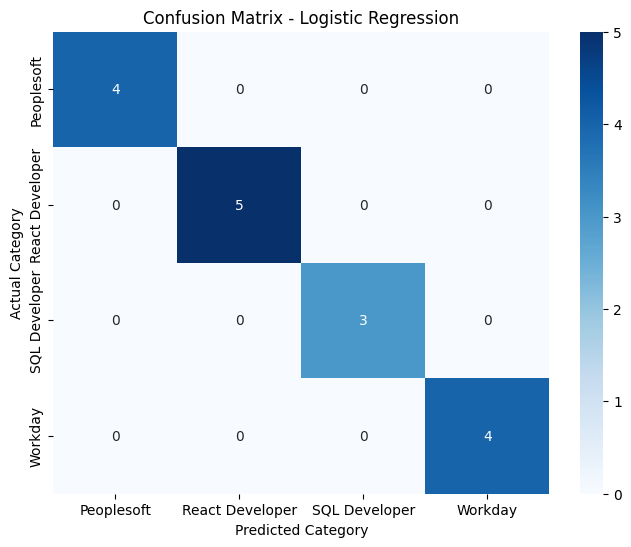

In [67]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.title('Confusion Matrix - Logistic Regression')

plt.show()

In [68]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

In [69]:
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=5000,
        stop_words='english',
        ngram_range=(1, 2)
    )),

    ('classifier', LogisticRegression(
        max_iter=2000
    ))
])

In [70]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [71]:
scores = cross_validate(
    pipeline,
    X,
    y,
    cv=cv,
    scoring=['accuracy', 'f1_macro'],
    return_train_score=True
)

In [72]:
import numpy as np

print("Accuracy scores:", scores['test_accuracy'])

print("Mean Accuracy:", np.mean(scores['test_accuracy']))

print("Accuracy Standard Deviation:", np.std(scores['test_accuracy']))

print("Macro F1 scores:", scores['test_f1_macro'])

print("Mean Macro F1:", np.mean(scores['test_f1_macro']))

Accuracy scores: [1. 1. 1. 1. 1.]
Mean Accuracy: 1.0
Accuracy Standard Deviation: 0.0
Macro F1 scores: [1. 1. 1. 1. 1.]
Mean Macro F1: 1.0


In [73]:
from sklearn.naive_bayes import MultinomialNB
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [74]:
y_pred_nb = nb_model.predict(X_test_tfidf)

In [75]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_nb))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_nb,
    zero_division=0
))

Accuracy: 1.0

Classification Report:
                 precision    recall  f1-score   support

     Peoplesoft       1.00      1.00      1.00         4
React Developer       1.00      1.00      1.00         5
  SQL Developer       1.00      1.00      1.00         3
        Workday       1.00      1.00      1.00         4

       accuracy                           1.00        16
      macro avg       1.00      1.00      1.00        16
   weighted avg       1.00      1.00      1.00        16



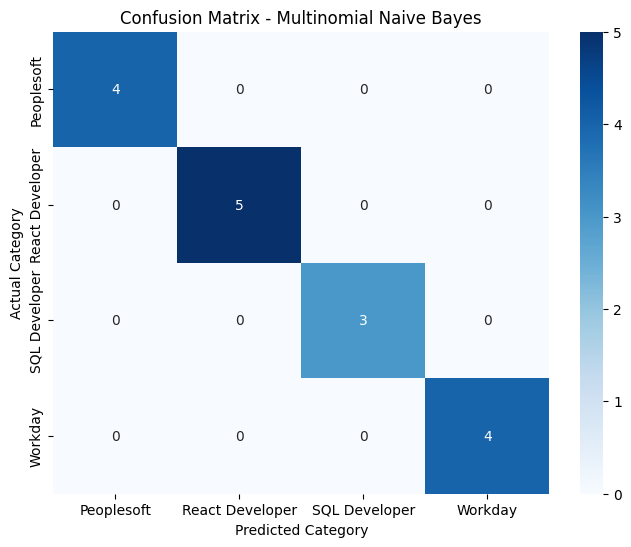

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm_nb = confusion_matrix(
    y_test,
    y_pred_nb,
    labels=nb_model.classes_
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=nb_model.classes_,
    yticklabels=nb_model.classes_
)

plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.title('Confusion Matrix - Multinomial Naive Bayes')

plt.show()

In [77]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer

nb_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=5000,
        stop_words='english',
        ngram_range=(1, 2)
    )),

    ('classifier', MultinomialNB())
])

In [78]:
nb_cv_scores = cross_validate(
    nb_pipeline,
    X,
    y,
    cv=cv,
    scoring=['accuracy', 'f1_macro'],
    return_train_score=True
)

In [79]:
import numpy as np

print("Accuracy scores:", nb_cv_scores['test_accuracy'])

print("Mean Accuracy:", np.mean(nb_cv_scores['test_accuracy']))

print("Accuracy Standard Deviation:", np.std(nb_cv_scores['test_accuracy']))

print("Macro F1 scores:", nb_cv_scores['test_f1_macro'])

print("Mean Macro F1:", np.mean(nb_cv_scores['test_f1_macro']))

Accuracy scores: [1. 1. 1. 1. 1.]
Mean Accuracy: 1.0
Accuracy Standard Deviation: 0.0
Macro F1 scores: [1. 1. 1. 1. 1.]
Mean Macro F1: 1.0


In [80]:
from sklearn.svm import LinearSVC

In [81]:
svm_model = LinearSVC()
svm_model.fit(X_train_tfidf, y_train)

,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001
,C,1.0
,multi_class,'ovr'
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,verbose,0
,random_state,None


In [82]:
y_pred_svm = svm_model.predict(X_test_tfidf)

In [83]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm, zero_division=0))

Accuracy: 1.0

Classification Report:
                 precision    recall  f1-score   support

     Peoplesoft       1.00      1.00      1.00         4
React Developer       1.00      1.00      1.00         5
  SQL Developer       1.00      1.00      1.00         3
        Workday       1.00      1.00      1.00         4

       accuracy                           1.00        16
      macro avg       1.00      1.00      1.00        16
   weighted avg       1.00      1.00      1.00        16



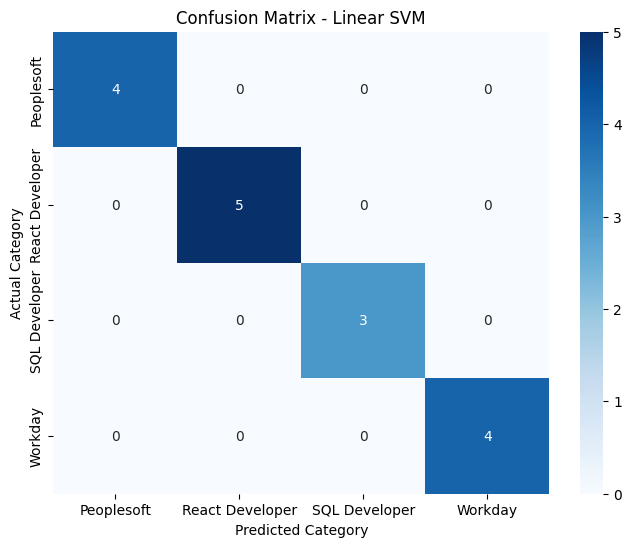

In [84]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_svm = confusion_matrix(y_test, y_pred_svm, labels=svm_model.classes_)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=svm_model.classes_,
    yticklabels=svm_model.classes_
)

plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.title('Confusion Matrix - Linear SVM')

plt.show()

In [85]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=5000,
        stop_words='english',
        ngram_range=(1, 2)
    )),
    ('classifier', LinearSVC())
])

svm_cv_scores = cross_validate(
    svm_pipeline,
    X,
    y,
    cv=cv,
    scoring=['accuracy', 'f1_macro'],
    return_train_score=True
)

In [86]:
import numpy as np

print("Accuracy scores:", svm_cv_scores['test_accuracy'])

print("Mean Accuracy:",
      np.mean(svm_cv_scores['test_accuracy']))

print("Accuracy Standard Deviation:",
      np.std(svm_cv_scores['test_accuracy']))

print("Macro F1 scores:",
      svm_cv_scores['test_f1_macro'])

print("Mean Macro F1:",
      np.mean(svm_cv_scores['test_f1_macro']))

Accuracy scores: [1. 1. 1. 1. 1.]
Mean Accuracy: 1.0
Accuracy Standard Deviation: 0.0
Macro F1 scores: [1. 1. 1. 1. 1.]
Mean Macro F1: 1.0


In [87]:
from sklearn.ensemble import RandomForestClassifier

In [88]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train_tfidf, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [89]:
y_pred_rf = rf_model.predict(X_test_tfidf)

In [90]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Accuracy: 1.0

Classification Report:
                 precision    recall  f1-score   support

     Peoplesoft       1.00      1.00      1.00         4
React Developer       1.00      1.00      1.00         5
  SQL Developer       1.00      1.00      1.00         3
        Workday       1.00      1.00      1.00         4

       accuracy                           1.00        16
      macro avg       1.00      1.00      1.00        16
   weighted avg       1.00      1.00      1.00        16



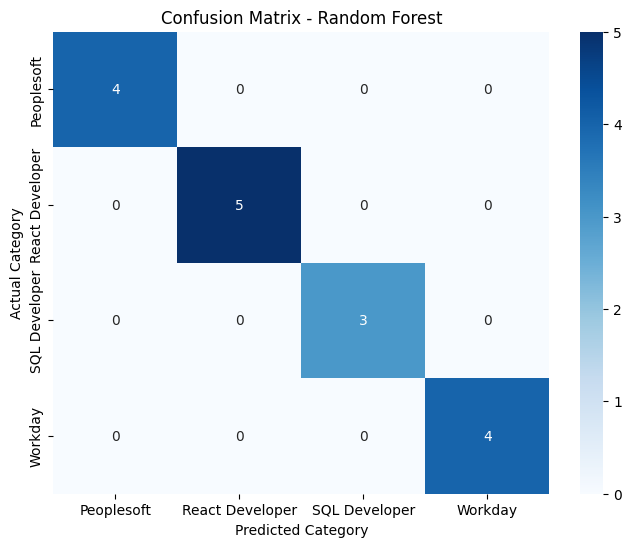

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(y_test, y_pred_rf, labels=rf_model.classes_)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.title('Confusion Matrix - Random Forest')

plt.show()

In [92]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer

rf_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=5000,
        stop_words='english',
        ngram_range=(1, 2)
    )),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_cv_scores = cross_validate(
    rf_pipeline,
    X,
    y,
    cv=cv,
    scoring=['accuracy', 'f1_macro'],
    return_train_score=True
)

In [93]:


print("Accuracy scores:", rf_cv_scores['test_accuracy'])

print("Mean Accuracy:",
      np.mean(rf_cv_scores['test_accuracy']))

print("Accuracy Standard Deviation:",
      np.std(rf_cv_scores['test_accuracy']))

print("Macro F1 scores:",
      rf_cv_scores['test_f1_macro'])

print("Mean Macro F1:",
      np.mean(rf_cv_scores['test_f1_macro']))

Accuracy scores: [1.         0.875      1.         0.93333333 1.        ]
Mean Accuracy: 0.9616666666666667
Accuracy Standard Deviation: 0.05044248650140518
Macro F1 scores: [1.         0.875      1.         0.93650794 1.        ]
Mean Macro F1: 0.9623015873015873


In [94]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

In [95]:
le = LabelEncoder()

y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

In [96]:
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    eval_metric='mlogloss'
)

In [97]:
xgb_model.fit(X_train_tfidf, y_train_encoded)

,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'mlogloss'


In [98]:
y_pred_xgb_encoded = xgb_model.predict(X_test_tfidf)

y_pred_xgb = le.inverse_transform(y_pred_xgb_encoded)

In [99]:


print("Accuracy:", accuracy_score(y_test, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb, zero_division=0))

Accuracy: 1.0

Classification Report:
                 precision    recall  f1-score   support

     Peoplesoft       1.00      1.00      1.00         4
React Developer       1.00      1.00      1.00         5
  SQL Developer       1.00      1.00      1.00         3
        Workday       1.00      1.00      1.00         4

       accuracy                           1.00        16
      macro avg       1.00      1.00      1.00        16
   weighted avg       1.00      1.00      1.00        16



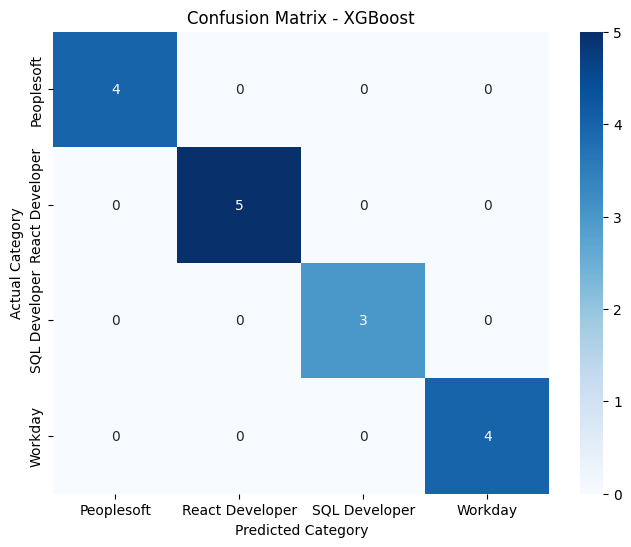

In [100]:


cm_xgb = confusion_matrix(y_test, y_pred_xgb, labels=le.classes_)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.title('Confusion Matrix - XGBoost')

plt.show()

In [101]:
y_encoded = le.fit_transform(y)

In [102]:


xgb_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=5000,
        stop_words='english',
        ngram_range=(1, 2)
    )),
    ('classifier', XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        random_state=42,
        eval_metric='mlogloss'
    ))
])

In [103]:
xgb_cv_scores = cross_validate(
    xgb_pipeline,
    X,
    y_encoded,
    cv=cv,
    scoring=['accuracy', 'f1_macro'],
    return_train_score=True
)

In [104]:


print("Accuracy scores:", xgb_cv_scores['test_accuracy'])

print("Mean Accuracy:",
      np.mean(xgb_cv_scores['test_accuracy']))

print("Accuracy Standard Deviation:",
      np.std(xgb_cv_scores['test_accuracy']))

print("Macro F1 scores:",
      xgb_cv_scores['test_f1_macro'])

print("Mean Macro F1:",
      np.mean(xgb_cv_scores['test_f1_macro']))

Accuracy scores: [1.         0.9375     1.         0.86666667 0.93333333]
Mean Accuracy: 0.9475
Accuracy Standard Deviation: 0.04969350505291857
Macro F1 scores: [1.         0.89393939 1.         0.86607143 0.92222222]
Mean Macro F1: 0.936446608946609


In [105]:
from sklearn.tree import DecisionTreeClassifier

In [106]:
dt_model = DecisionTreeClassifier(
    random_state=42
)
dt_model.fit(X_train_tfidf, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [107]:
y_pred_dt = dt_model.predict(X_test_tfidf)

In [108]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, zero_division=0))

Accuracy: 1.0

Classification Report:
                 precision    recall  f1-score   support

     Peoplesoft       1.00      1.00      1.00         4
React Developer       1.00      1.00      1.00         5
  SQL Developer       1.00      1.00      1.00         3
        Workday       1.00      1.00      1.00         4

       accuracy                           1.00        16
      macro avg       1.00      1.00      1.00        16
   weighted avg       1.00      1.00      1.00        16



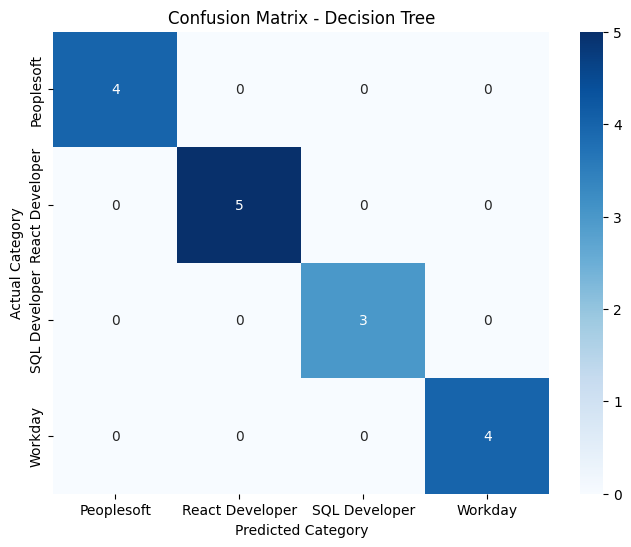

In [109]:


cm_dt = confusion_matrix(y_test, y_pred_dt, labels=dt_model.classes_)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=dt_model.classes_,
    yticklabels=dt_model.classes_
)

plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.title('Confusion Matrix - Decision Tree')

plt.show()

In [110]:

dt_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=5000,
        stop_words='english',
        ngram_range=(1, 2)
    )),
    ('classifier', DecisionTreeClassifier(
        random_state=42
    ))
])

dt_cv_scores = cross_validate(
    dt_pipeline,
    X,
    y,
    cv=cv,
    scoring=['accuracy', 'f1_macro'],
    return_train_score=True
)

In [111]:


print("Accuracy scores:", dt_cv_scores['test_accuracy'])

print("Mean Accuracy:",
      np.mean(dt_cv_scores['test_accuracy']))

print("Accuracy Standard Deviation:",
      np.std(dt_cv_scores['test_accuracy']))

print("Macro F1 scores:",
      dt_cv_scores['test_f1_macro'])

print("Mean Macro F1:",
      np.mean(dt_cv_scores['test_f1_macro']))

Accuracy scores: [1. 1. 1. 1. 1.]
Mean Accuracy: 1.0
Accuracy Standard Deviation: 0.0
Macro F1 scores: [1. 1. 1. 1. 1.]
Mean Macro F1: 1.0


In [112]:


model_results = {
    'Logistic Regression': scores,
    'Multinomial Naive Bayes': nb_cv_scores,
    'Linear SVM': svm_cv_scores,
    'Random Forest': rf_cv_scores,
    'XGBoost': xgb_cv_scores,
    'Decision Tree': dt_cv_scores
}

comparison = []

for model_name, result in model_results.items():

    comparison.append({
        'Model': model_name,
        'Mean Accuracy': np.mean(result['test_accuracy']),
        'Accuracy Std': np.std(result['test_accuracy']),
        'Mean Macro F1': np.mean(result['test_f1_macro']),
        'F1 Std': np.std(result['test_f1_macro'])
    })

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    by='Mean Macro F1',
    ascending=False
)

comparison_df

,Model,Mean Accuracy,Accuracy Std,Mean Macro F1,F1 Std
0,Logistic Regression,1.000000,0.000000,1.000000,0.000000
1,Multinomial Naive Bayes,1.000000,0.000000,1.000000,0.000000
2,Linear SVM,1.000000,0.000000,1.000000,0.000000
5,Decision Tree,1.000000,0.000000,1.000000,0.000000
3,Random Forest,0.961667,0.050442,0.962302,0.050101
4,XGBoost,0.947500,0.049694,0.936447,0.054845


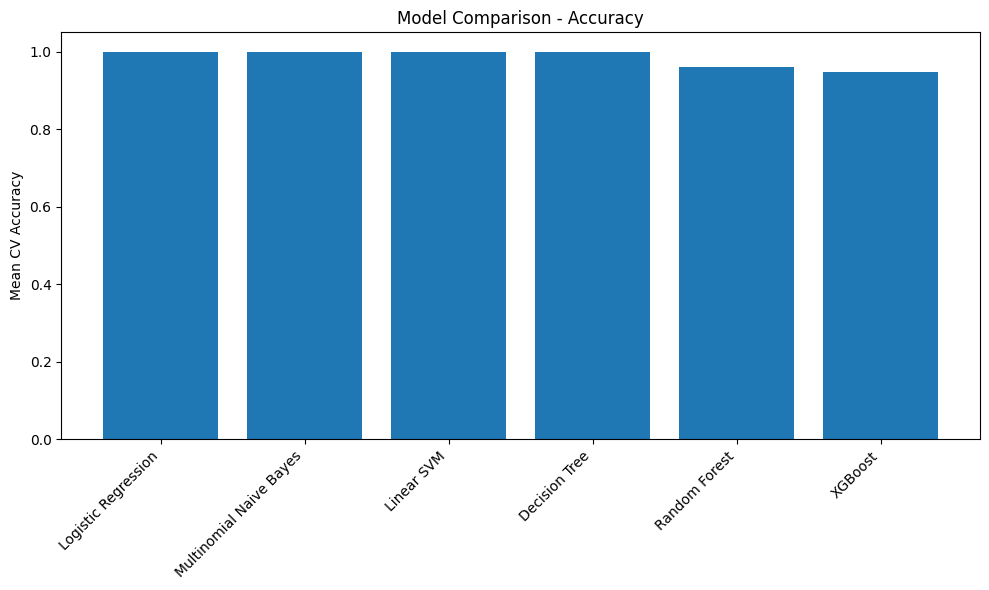

In [113]:


plt.figure(figsize=(10, 6))

plt.bar(
    comparison_df['Model'],
    comparison_df['Mean Accuracy']
)

plt.xticks(rotation=45, ha='right')
plt.ylabel('Mean CV Accuracy')
plt.title('Model Comparison - Accuracy')
plt.ylim(0, 1.05)

plt.tight_layout()
plt.show()

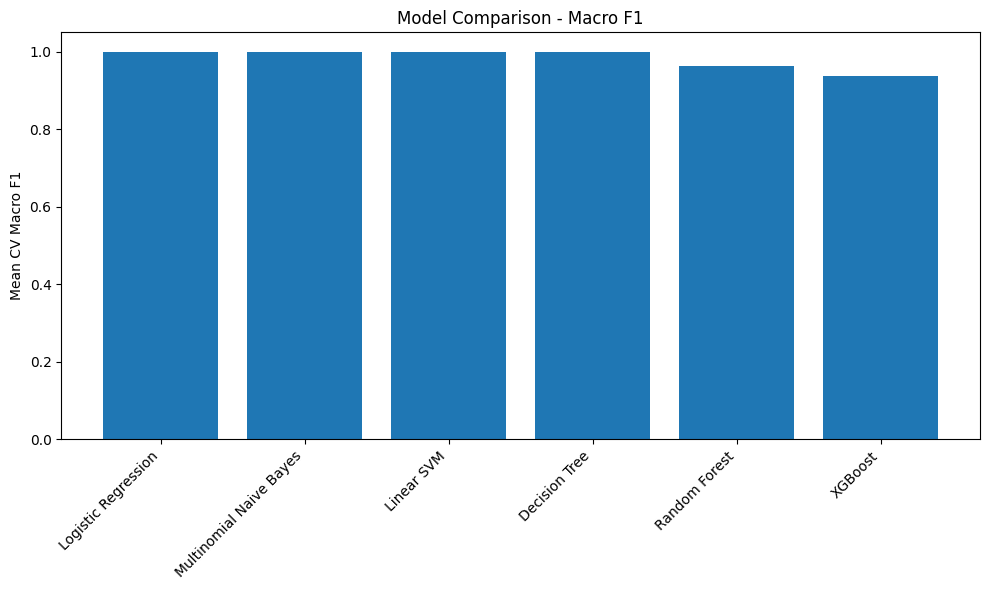

In [114]:
plt.figure(figsize=(10, 6))

plt.bar(
    comparison_df['Model'],
    comparison_df['Mean Macro F1']
)

plt.xticks(rotation=45, ha='right')
plt.ylabel('Mean CV Macro F1')
plt.title('Model Comparison - Macro F1')
plt.ylim(0, 1.05)

plt.tight_layout()
plt.show()

In [115]:
from sklearn.model_selection import GridSearchCV


In [116]:
lr_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words='english'
    )),
    ('classifier', LogisticRegression(
        max_iter=2000
    ))
])

In [117]:
lr_param_grid = {
    'tfidf__max_features': [3000, 5000],
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'classifier__C': [0.1, 1, 10]
}

In [118]:
lr_grid = GridSearchCV(
    lr_pipeline,
    lr_param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

In [119]:
lr_grid.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,estimator,Pipeline(step..._iter=2000))])
,param_grid,"{'classifier__C': [0.1, 1, ...], 'tfidf__max_features': [3000, 5000], 'tfidf__ngram_range': [(1, ...), (1, ...)]}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,input,'content'


In [120]:
print("Best Parameters:")
print(lr_grid.best_params_)

print("\nBest CV Macro F1:")
print(lr_grid.best_score_)

Best Parameters:
{'classifier__C': 1, 'tfidf__max_features': 3000, 'tfidf__ngram_range': (1, 1)}

Best CV Macro F1:
1.0


In [121]:
best_lr = lr_grid.best_estimator_

y_pred_lr_tuned = best_lr.predict(X_test)

from sklearn.metrics import accuracy_score, classification_report

print("Test Accuracy:",
      accuracy_score(y_test, y_pred_lr_tuned))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr_tuned,
    zero_division=0
))

Test Accuracy: 1.0

Classification Report:
                 precision    recall  f1-score   support

     Peoplesoft       1.00      1.00      1.00         4
React Developer       1.00      1.00      1.00         5
  SQL Developer       1.00      1.00      1.00         3
        Workday       1.00      1.00      1.00         4

       accuracy                           1.00        16
      macro avg       1.00      1.00      1.00        16
   weighted avg       1.00      1.00      1.00        16



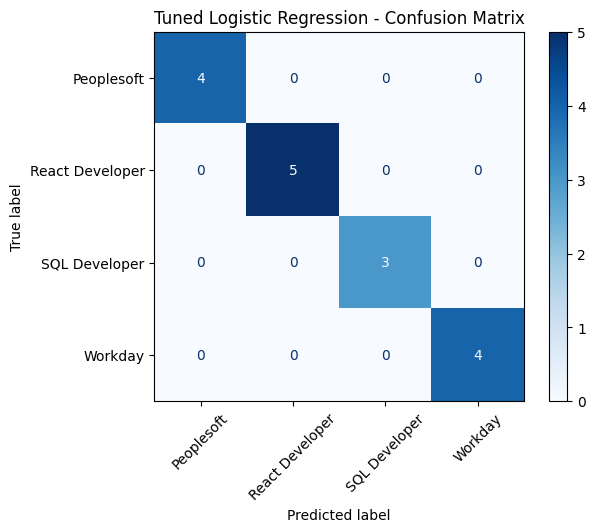

In [122]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_lr_tuned, labels=best_lr.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_lr.classes_
)

disp.plot(cmap='Blues', xticks_rotation=45)
plt.title("Tuned Logistic Regression - Confusion Matrix")
plt.show()

In [123]:
nb_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english')),
    ('classifier', MultinomialNB())
])

In [124]:
nb_param_grid = {
    'tfidf__max_features': [3000, 5000],
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'classifier__alpha': [0.01, 0.1, 0.5, 1.0, 2.0]
}

In [125]:
nb_grid = GridSearchCV(
    nb_pipeline,
    nb_param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

In [126]:
nb_grid.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,estimator,Pipeline(step...inomialNB())])
,param_grid,"{'classifier__alpha': [0.01, 0.1, ...], 'tfidf__max_features': [3000, 5000], 'tfidf__ngram_range': [(1, ...), (1, ...)]}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,input,'content'


In [127]:
print("Best Parameters:")
print(nb_grid.best_params_)

print("\nBest CV Macro F1:")
print(nb_grid.best_score_)

Best Parameters:
{'classifier__alpha': 0.01, 'tfidf__max_features': 3000, 'tfidf__ngram_range': (1, 2)}

Best CV Macro F1:
1.0


In [128]:
best_nb = nb_grid.best_estimator_

y_pred_nb_tuned = best_nb.predict(X_test)

from sklearn.metrics import accuracy_score, classification_report

print("Test Accuracy:", accuracy_score(y_test, y_pred_nb_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb_tuned, zero_division=0))

Test Accuracy: 1.0

Classification Report:
                 precision    recall  f1-score   support

     Peoplesoft       1.00      1.00      1.00         4
React Developer       1.00      1.00      1.00         5
  SQL Developer       1.00      1.00      1.00         3
        Workday       1.00      1.00      1.00         4

       accuracy                           1.00        16
      macro avg       1.00      1.00      1.00        16
   weighted avg       1.00      1.00      1.00        16



In [129]:
svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english')),
    ('classifier', LinearSVC())
])

In [130]:
svm_param_grid = {
    'tfidf__max_features': [3000, 5000],
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'classifier__C': [0.1, 1, 10, 100]
}

In [131]:
svm_grid = GridSearchCV(
    svm_pipeline,
    svm_param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

In [132]:
svm_grid.fit(X_train, y_train)

Fitting 5 folds for each of 16 candidates, totalling 80 fits


,estimator,Pipeline(step...LinearSVC())])
,param_grid,"{'classifier__C': [0.1, 1, ...], 'tfidf__max_features': [3000, 5000], 'tfidf__ngram_range': [(1, ...), (1, ...)]}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,input,'content'


In [133]:
print("Best Parameters:")
print(svm_grid.best_params_)

print("\nBest CV Macro F1:")
print(svm_grid.best_score_)

Best Parameters:
{'classifier__C': 0.1, 'tfidf__max_features': 3000, 'tfidf__ngram_range': (1, 1)}

Best CV Macro F1:
1.0


In [134]:
best_svm = svm_grid.best_estimator_

y_pred_svm_tuned = best_svm.predict(X_test)

from sklearn.metrics import accuracy_score, classification_report

print("Test Accuracy:", accuracy_score(y_test, y_pred_svm_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm_tuned, zero_division=0))

Test Accuracy: 1.0

Classification Report:
                 precision    recall  f1-score   support

     Peoplesoft       1.00      1.00      1.00         4
React Developer       1.00      1.00      1.00         5
  SQL Developer       1.00      1.00      1.00         3
        Workday       1.00      1.00      1.00         4

       accuracy                           1.00        16
      macro avg       1.00      1.00      1.00        16
   weighted avg       1.00      1.00      1.00        16



In [135]:


tuned_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Multinomial Naive Bayes',
        'Linear SVM'
    ],
    'Best CV Macro F1': [
        lr_grid.best_score_,
        nb_grid.best_score_,
        svm_grid.best_score_
    ],
    'Test Accuracy': [
        accuracy_score(y_test, y_pred_lr_tuned),
        accuracy_score(y_test, y_pred_nb_tuned),
        accuracy_score(y_test, y_pred_svm_tuned)
    ],
    'Test Macro F1': [
        1.0,
        1.0,
        1.0
    ]
})


In [136]:
tuned_results.style.format({
    'Best CV Macro F1': '{:.4f}',
    'Test Accuracy': '{:.4f}',
    'Test Macro F1': '{:.4f}'
})

,Model,Best CV Macro F1,Test Accuracy,Test Macro F1
0,Logistic Regression,1.0000,1.0000,1.0000
1,Multinomial Naive Bayes,1.0000,1.0000,1.0000
2,Linear SVM,1.0000,1.0000,1.0000


In [137]:
# Extract the trained Logistic Regression classifier
lr_classifier = best_lr.named_steps['classifier']

# Extract the TF-IDF vectorizer
lr_vectorizer = best_lr.named_steps['tfidf']

# Get feature names
feature_names = lr_vectorizer.get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = lr_classifier.coef_

# Get class names
class_names = lr_classifier.classes_

print("Classes:", class_names)
print("Coefficient shape:", coefficients.shape)
print("Feature names shape:", feature_names.shape)

Classes: ['Peoplesoft' 'React Developer' 'SQL Developer' 'Workday']
Coefficient shape: (4, 3000)
Feature names shape: (3000,)


In [138]:
top_features = {}

for i, class_name in enumerate(class_names):

    class_coefficients = coefficients[i]

    top_indices = np.argsort(class_coefficients)[-20:][::-1]

    top_words = feature_names[top_indices]
    top_weights = class_coefficients[top_indices]

    top_features[class_name] = pd.DataFrame({
        'Word': top_words,
        'Coefficient': top_weights
    })

    print(f"\nTop 20 features for {class_name}")

    print(top_features[class_name])


Top 20 features for Peoplesoft
            Word  Coefficient
0     peoplesoft     1.294528
1    application     0.494460
2         people     0.490805
3           fscm     0.433246
4          tools     0.343113
5         oracle     0.318438
6         server     0.287753
7        servers     0.272161
8       designer     0.244638
9    peopletools     0.243922
10            ps     0.239133
11            55     0.238441
12     scheduler     0.232326
13       upgrade     0.217695
14        engine     0.207761
15       domains     0.206626
16      applying     0.200475
17       process     0.196911
18    production     0.196623
19  environments     0.192800

Top 20 features for React Developer
            Word  Coefficient
0          react     0.956417
1             js     0.751618
2     javascript     0.555393
3           html     0.442476
4             ui     0.418204
5           css3     0.363011
6      bootstrap     0.346587
7            css     0.331028
8          html5     0.311275
9

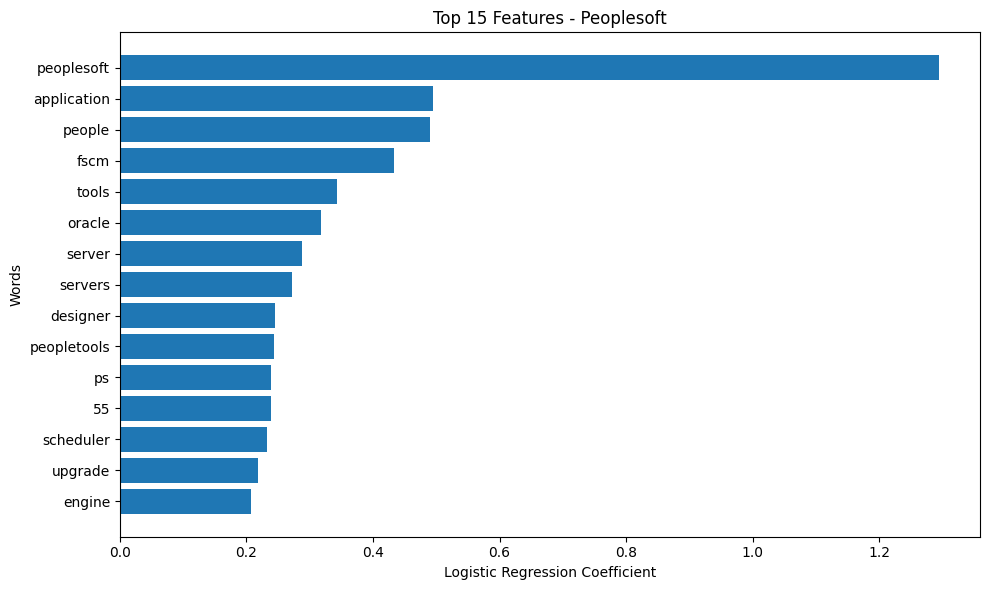

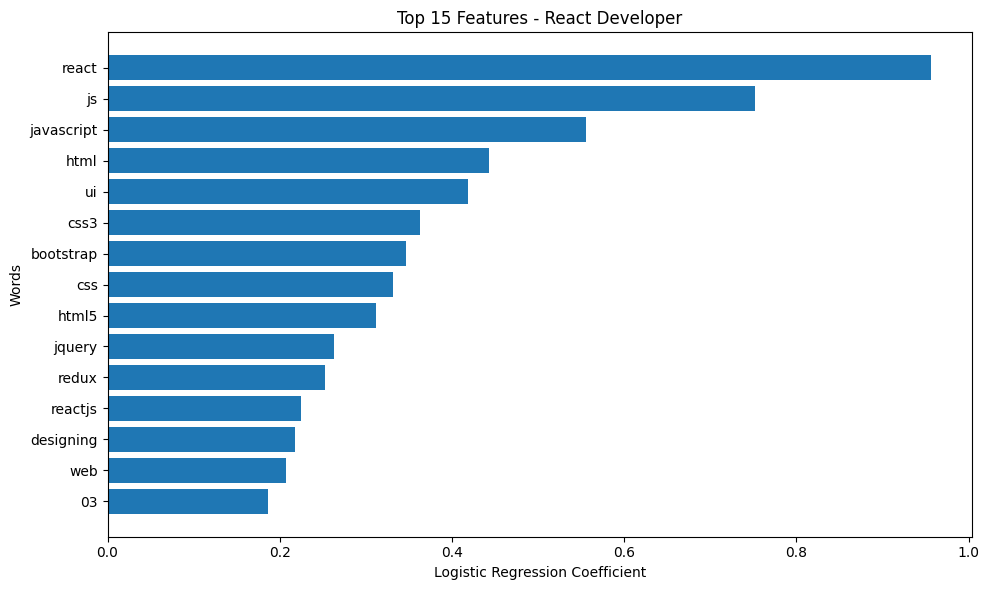

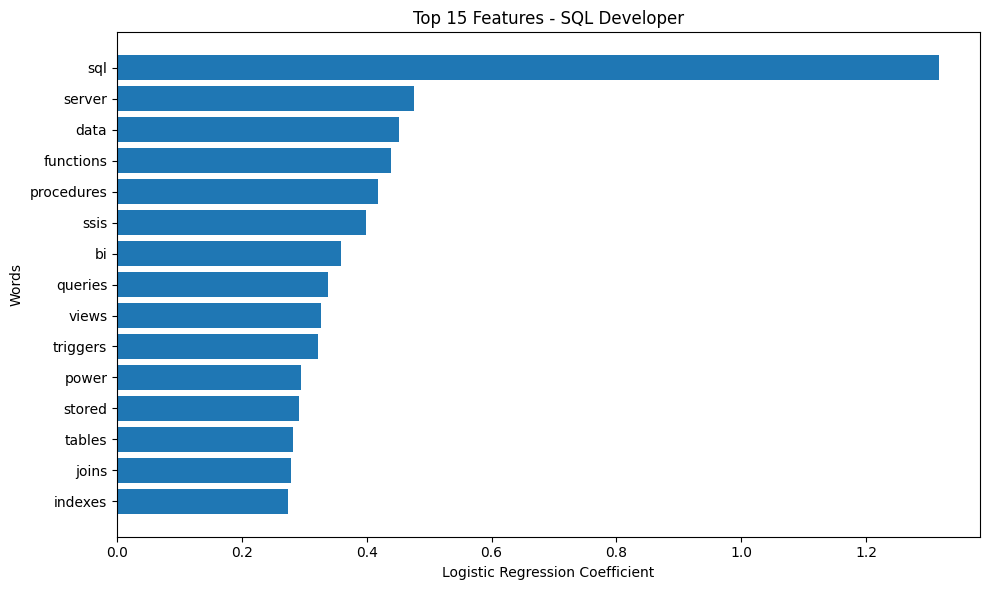

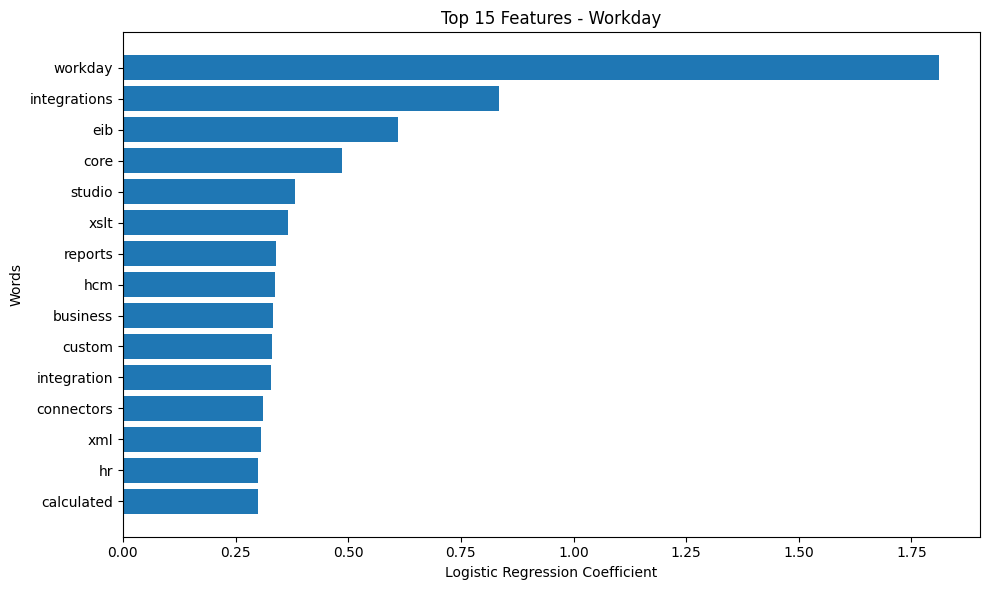

In [139]:
import matplotlib.pyplot as plt

for class_name, df_features in top_features.items():

    top_15 = df_features.head(15).sort_values(
        by='Coefficient',
        ascending=True
    )

    plt.figure(figsize=(10, 6))

    plt.barh(
        top_15['Word'],
        top_15['Coefficient']
    )

    plt.title(f"Top 15 Features - {class_name}")
    plt.xlabel("Logistic Regression Coefficient")
    plt.ylabel("Words")

    plt.tight_layout()
    plt.show()

In [140]:
sample_resume = X_test.iloc[0]

probabilities = best_lr.predict_proba([sample_resume])

print(probabilities)


[[0.18536853 0.1716044  0.51698042 0.12604665]]


In [141]:
print(best_lr.classes_)

['Peoplesoft' 'React Developer' 'SQL Developer' 'Workday']


In [142]:


probabilities = best_lr.predict_proba([sample_resume])[0]

probability_df = pd.DataFrame({
    'Job Role': best_lr.classes_,
    'Probability': probabilities
})

probability_df = probability_df.sort_values(
    by='Probability',
    ascending=False
)

probability_df

,Job Role,Probability
2,SQL Developer,0.516980
0,Peoplesoft,0.185369
1,React Developer,0.171604
3,Workday,0.126047


In [143]:
def predict_resume(text):

    # Predict the job role
    prediction = best_lr.predict([text])[0]

    # Obtain probabilities for all classes
    probabilities = best_lr.predict_proba([text])[0]

    # Create probability dataframe
    result = pd.DataFrame({
        'Job Role': best_lr.classes_,
        'Probability': probabilities
    })

    # Sort from highest to lowest
    result = result.sort_values(
        by='Probability',
        ascending=False
    )

    return prediction, result

In [144]:
predicted_role, probability_result = predict_resume(sample_resume)

print("Predicted Job Role:", predicted_role)

print("\nProbability Ranking:")
display(probability_result)

Predicted Job Role: SQL Developer

Probability Ranking:


,Job Role,Probability
2,SQL Developer,0.516980
0,Peoplesoft,0.185369
1,React Developer,0.171604
3,Workday,0.126047


In [145]:
sample_resume_2 = X_test.iloc[1]

predicted_role_2, probability_result_2 = predict_resume(sample_resume_2)

print("Predicted Job Role:", predicted_role_2)

display(probability_result_2)

Predicted Job Role: React Developer


,Job Role,Probability
1,React Developer,0.677221
0,Peoplesoft,0.129647
2,SQL Developer,0.098782
3,Workday,0.094350


In [146]:
from docx import Document
from pypdf import PdfReader
import io

In [147]:
def extract_resume_text(file):

    file_extension = file.name.lower().split('.')[-1]

    if file_extension == 'docx':

        document = Document(file)

        text = []

        for paragraph in document.paragraphs:
            text.append(paragraph.text)

        return '\n'.join(text)

    elif file_extension == 'pdf':

        reader = PdfReader(file)

        text = []

        for page in reader.pages:
            page_text = page.extract_text()

            if page_text:
                text.append(page_text)

        return '\n'.join(text)

    else:

        raise ValueError("Unsupported file format")

In [227]:
file_path=r"C:\Users\BALAJI\OneDrive\Desktop\excelr_project_2\Dataset\P637 Dataset\Resumes_Docx\Peoplesoft Resume\Peoplesoft Admin_SirazuddinMohammad.docx"

In [228]:
from docx import Document

def extract_resume_text(file_path):

    document = Document(file_path)

    text = []

    for paragraph in document.paragraphs:
        text.append(paragraph.text)

    resume_text = '\n'.join(text)

    return resume_text

In [229]:
import re

def clean_resume(text):

    text = text.lower()

    text = re.sub(r'[^a-z\s]', ' ', text)

    text = re.sub(r'\s+', ' ', text)

    return text.strip()

In [230]:
def classify_resume_file(file_path):

    try:

        # Extract resume text
        resume_text = extract_resume_text(file_path)

        if not resume_text.strip():
            raise ValueError("No text extracted from resume")

        # Clean extracted text
        cleaned_resume = clean_resume(resume_text)

        # Predict job role
        predicted_role = best_lr.predict([cleaned_resume])[0]

        # Get probabilities
        probabilities = best_lr.predict_proba([cleaned_resume])[0]

        # Create result DataFrame
        result = pd.DataFrame({
            'Job Role': best_lr.classes_,
            'Probability': probabilities
        })

        # Sort probabilities
        result = result.sort_values(
            by='Probability',
            ascending=False
        ).reset_index(drop=True)

        # Return exactly 3 values
        return resume_text, predicted_role, result

    except Exception as e:

        print("Error processing resume:", e)

        # Return exactly 3 values
        return None, None, None

In [231]:
resume_text, predicted_role, result = classify_resume_file(file_path)

print("Predicted Job Role:", predicted_role)

display(result)

Predicted Job Role: Peoplesoft


,Job Role,Probability
0,Peoplesoft,0.687575
1,React Developer,0.123229
2,SQL Developer,0.103344
3,Workday,0.085852


In [232]:
print("Predicted Job Role:", predicted_role)

display(result)

Predicted Job Role: Peoplesoft


,Job Role,Probability
0,Peoplesoft,0.687575
1,React Developer,0.123229
2,SQL Developer,0.103344
3,Workday,0.085852


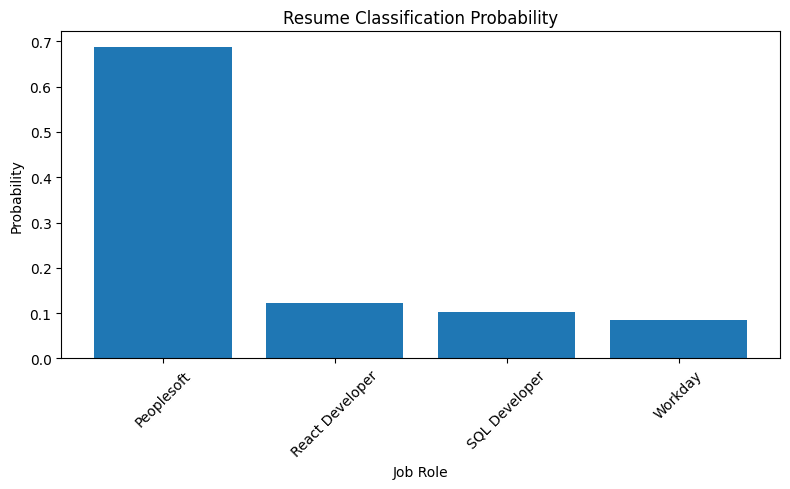

In [233]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(result['Job Role'], result['Probability'])

plt.title("Resume Classification Probability")
plt.xlabel("Job Role")
plt.ylabel("Probability")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [235]:
resume_text, predicted_role, result = classify_resume_file(file_path)

highest_probability = result.iloc[0]['Probability']

print("Predicted Job Role:", predicted_role)
print("Model Probability:", round(highest_probability * 100, 2), "%")

if highest_probability >= 0.80:
    print("Prediction Strength: High")
elif highest_probability >= 0.50:
    print("Prediction Strength: Moderate")
else:
    print("Prediction Strength: Low")

Predicted Job Role: Peoplesoft
Model Probability: 68.76 %
Prediction Strength: Moderate


In [236]:
from pypdf import PdfReader

In [237]:
def extract_pdf(file_path):

    reader = PdfReader(file_path)

    text = []

    for page in reader.pages:

        page_text = page.extract_text()

        if page_text:
            text.append(page_text)

    resume_text = '\n'.join(text)

    return resume_text

In [238]:
import win32com.client
import tempfile
import os
import shutil

In [239]:
def extract_doc(file_path):

    word = win32com.client.DispatchEx("Word.Application")
    word.Visible = False

    temp_dir = tempfile.mkdtemp()

    converted_path = os.path.join(
        temp_dir,
        "converted_resume.docx"
    )

    doc = None

    try:

        doc = word.Documents.Open(os.path.abspath(file_path))

        doc.SaveAs2(
            os.path.abspath(converted_path),
            FileFormat=16
        )

        doc.Close(False)
        doc = None

        # Use your already existing DOCX extraction function
        resume_text = extract_resume_text(converted_path)

        return resume_text

    finally:

        if doc is not None:
            doc.Close(False)

        word.Quit()

        shutil.rmtree(temp_dir, ignore_errors=True)

In [240]:
file=r"C:\Users\BALAJI\OneDrive\Desktop\excelr_project_2\Dataset\P637 Dataset\Resumes_Docx\React Developer\Reactjs Developer_Prabakaran_Musquare Technologies.pdf"


resume_text = extract_pdf(file)

print(resume_text[:2000])

   
Page | 1  
 
Name: M. Prabakaran 
Title: UI Developer 
 
PROFESSIONAL SUMMARY 
 
● 2.4+ years of Professional IT experience as a software developer having knowledge on different UI based 
Application. 
● Hands on experience in HTML, CSS, JS, ReactJS.   
● Hands on experience in handling UI interaction, Design methodology. 
● Handling In-App purchase, uploading and maintaining apps in play store. 
● Hands on experience with customization over base-product depends on client requirement.  
● Cohesive team worker, having strong analytical, problem solving and interpersonal skills. 
 
EDUCATION 
 
● Completed on 2017 Bachelor of Technology (ECE), PRIST University, Tamil Nadu. 
● Completed on 2012 Higher Secondary, Mount Park Hr Sec School, Thiyagadurgam, Tamil Nadu. 
● Completed on 2010 SSLC, Krishnasamy Hr Sec School, Cuddalore, Tamil Nadu. 
 
SKILLS 
 
Operating System Windows, Unix,Mac 
Programming Languages HTML, CSS, JS, React 
Mobile App Development Windows and Android Apps 
Desig

In [241]:
file_path = r"C:\Users\BALAJI\OneDrive\Desktop\excelr_project_2\Dataset\P637 Dataset\Resumes_Docx\Peoplesoft Resume\Peoplesoft Admin_Priyanka Ramadoss.doc"

resume_text = extract_doc(file_path)

print(resume_text[:2000])

Priyanka Ramadoss
61/46, MountPleasant, 
Coonoor
The Nilgiris- 643102                                                                                            

Career Objective

To excel as a software professional by working in a learning and challenging environment and utilize the skills and knowledge through diligence, dedication and ensure maximum contribution to the growth of the organization I work for.

Profile Summary

An Adept IT professional with 4.11 years (September 2016 - present) of experience as Peoplesoft Admin with Accenture

Professional Summary

PeopleSoft Administrator (September 2016-Present)

Experience in PeopleSoft Administration for Finance application.
Proficient in creating and configuring PeopleSoft components like Web server, Application server and process schedulers.
Active monitoring in Non production databases and applications.
Knowledgeable on PeopleSoft migrations using application designer, data mover and taking compare reports and also moving the c

In [242]:
def extract_res_text(file_path):

    extension = os.path.splitext(file_path)[1].lower()

    if extension == '.docx':
        resume_text = extract_resume_text(file_path)

    elif extension == '.doc':
        resume_text = extract_doc(file_path)

    elif extension == '.pdf':
        resume_text = extract_pdf(file_path)

    else:
        raise ValueError("Unsupported file format")

    return resume_text

In [246]:
file_path = r"C:\Users\BALAJI\OneDrive\Desktop\excelr_project_2\Dataset\P637 Dataset\Resumes_Docx\Peoplesoft Resume\Peoplesoft Admin_Priyanka Ramadoss.doc"

resume_text = extract_doc(file_path)

print(resume_text[:2000])

Priyanka Ramadoss
61/46, MountPleasant, 
Coonoor
The Nilgiris- 643102                                                                                            

Career Objective

To excel as a software professional by working in a learning and challenging environment and utilize the skills and knowledge through diligence, dedication and ensure maximum contribution to the growth of the organization I work for.

Profile Summary

An Adept IT professional with 4.11 years (September 2016 - present) of experience as Peoplesoft Admin with Accenture

Professional Summary

PeopleSoft Administrator (September 2016-Present)

Experience in PeopleSoft Administration for Finance application.
Proficient in creating and configuring PeopleSoft components like Web server, Application server and process schedulers.
Active monitoring in Non production databases and applications.
Knowledgeable on PeopleSoft migrations using application designer, data mover and taking compare reports and also moving the c

In [248]:
file_path=r"C:\Users\BALAJI\OneDrive\Desktop\excelr_project_2\Dataset\P637 Dataset\Resumes_Docx\Peoplesoft Resume\Peoplesoft Admin_SirazuddinMohammad.docx"
resume_text = extract_resume_text(file_path)

print(resume_text[:2000])















PROFILE SUMMARY

I have overall 6.8 years’ experience as PeopleSoft Administrator. Installed PeopleTools 8.55 from the scratch including its products. 
Experience in Peopletools 8.51, 8.54.08, 8.55.07&Application 9.0 and 9.2 (HRMS/FSCM). Deterministic approach towards problem solving & troubleshooting.
Proficient in Integration Broker.
Upgraded FSCM and HCM applications to PeopleTools 8.55.07 from PeopleTools 8.54.08.

EDUCATION

Graduated B-Tech in Electronics and Communication Engg. from M.V.G.R College of Engineering, Vizianagaram(JNTUK) with an aggregate of 68.93%.
Achieved 90% marks in 12th standard. Scored 86% in 10th standard.

ACHIEVEMENTS
Awarded Bravo in 2015 Q3, 2016 Q1 and Pat on Back in Q2, 2016, Q1, 2017 in Techahindra.
Awarded Associate of the month award and Innovator of the month (1 time). Awarded spot and pat on back in Capgemini

WORK EXPERIENCE
CAPGEMINI (MAY’19 – TILL NOW)
Production support for 5 finance environment and their respective non productio

In [249]:
file=r"C:\Users\BALAJI\OneDrive\Desktop\excelr_project_2\Dataset\P637 Dataset\Resumes_Docx\React Developer\Reactjs Developer_Prabakaran_Musquare Technologies.pdf"


resume_text = extract_pdf(file)

print(resume_text[:2000])

   
Page | 1  
 
Name: M. Prabakaran 
Title: UI Developer 
 
PROFESSIONAL SUMMARY 
 
● 2.4+ years of Professional IT experience as a software developer having knowledge on different UI based 
Application. 
● Hands on experience in HTML, CSS, JS, ReactJS.   
● Hands on experience in handling UI interaction, Design methodology. 
● Handling In-App purchase, uploading and maintaining apps in play store. 
● Hands on experience with customization over base-product depends on client requirement.  
● Cohesive team worker, having strong analytical, problem solving and interpersonal skills. 
 
EDUCATION 
 
● Completed on 2017 Bachelor of Technology (ECE), PRIST University, Tamil Nadu. 
● Completed on 2012 Higher Secondary, Mount Park Hr Sec School, Thiyagadurgam, Tamil Nadu. 
● Completed on 2010 SSLC, Krishnasamy Hr Sec School, Cuddalore, Tamil Nadu. 
 
SKILLS 
 
Operating System Windows, Unix,Mac 
Programming Languages HTML, CSS, JS, React 
Mobile App Development Windows and Android Apps 
Desig

In [250]:
import os
import joblib

os.makedirs("artifacts", exist_ok=True)

joblib.dump(best_lr, "artifacts/resume_classifier.pkl")

print("Model saved successfully!")

Model saved successfully!
